## Single layer perceptron to perform linear regression

x: Single input feature

y: target

parameters: wo, bo

**Objective:** to find a line that best fits the input data points -> linear regression

- loss function: mean squared error
- AF: linear
- Numerical differentiation to find gradient
- wo Matrix is initialized to a random numbers
- bo matrix is initialized to 0
- perform mini batch gradient decent
- here the epoch = 100 and batch size = 50

The equation of the original line: $y = 0.5x + 0.3$   

Predicted line: $\hat{y} = 0.485x + 0.304$



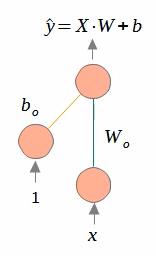

In [1]:
# [MXDL-1-07] 7.linear_regression.py
%load_ext autoreload
%autoreload 2
import numpy as np
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

from gradient_descent import gradient_descent

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
# Generate training data set
# y = 0.5x + 0.3 + noise
x = np.random.normal(0.0, 0.5, (1000, 1))
y = 0.5 * x + 0.3 + np.random.normal(0.0, 0.2, (1000, 1))

# Generate training, validation, and test data set
x_train, x_valid, y_train, y_valid = train_test_split(x, y)
x_test = np.linspace(-1.5, 1.5, 100).reshape(-1, 1)

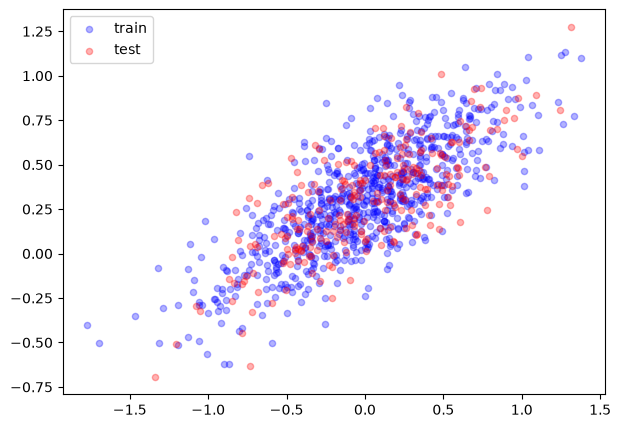

In [3]:
# See the data visually.
plt.figure(figsize=(7, 5))
plt.scatter(x_train, y_train, s=20, c='blue', alpha=0.3,
            label='train')
plt.scatter(x_valid, y_valid, s=20, c='red', alpha=0.3,
            label='test')
plt.legend()
plt.show()

In [4]:
# Create a single-layered ANN model.
n_input = x.shape[1]      # number of input neurons
n_output = 1              # number of output neurons
alpha = 0.01  # learning rate
h = 1e-4      # constant for numerical differentiation

# initialize the parameters randomly.
wo = np.random.normal(size=(n_input, n_output))
bo = np.zeros(shape=(1, n_output))
parameters = [wo, bo]

0: train_loss=0.1337, val_loss=0.1242
10: train_loss=0.0385, val_loss=0.0375
20: train_loss=0.0382, val_loss=0.0378
30: train_loss=0.0382, val_loss=0.0377
40: train_loss=0.0382, val_loss=0.0379
50: train_loss=0.0382, val_loss=0.0378
60: train_loss=0.0382, val_loss=0.0379
70: train_loss=0.0382, val_loss=0.0378
80: train_loss=0.0382, val_loss=0.0379
90: train_loss=0.0382, val_loss=0.0380


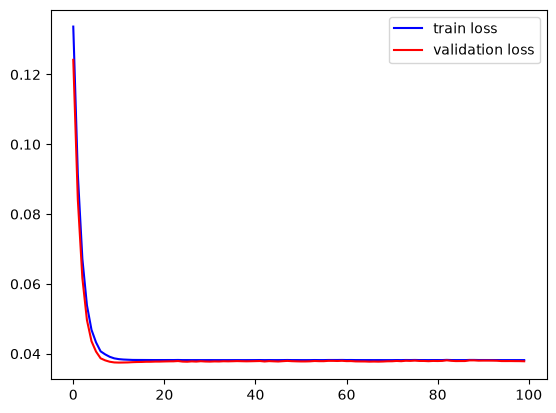

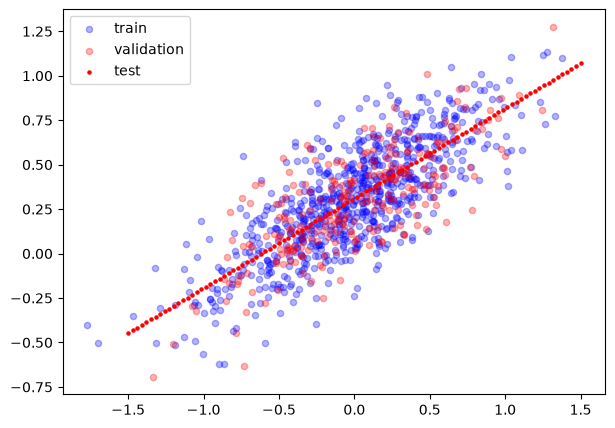

wo and bo: [array([[0.5053223]]), array([[0.31091103]])]


In [5]:
# loss function: mean squared error
def loss(y, y_hat):
    return np.mean(np.square(y - y_hat))

# Output from the ANN model: prediction process
def predict(x):
    p = parameters
    o_output = np.dot(x, p[0]) + p[1]  # output from output layer
    return o_output

# Perform training and track the loss history.
def train(x, y, x_val, y_val, epochs, batch_size):
    ht_loss = []  # loss history of training data
    hv_loss = []  # loss history of validation data
    for epoch in range(epochs):
        # measure the losses during training
        ht_loss.append(loss(y, predict(x)))
        hv_loss.append(loss(y_val, predict(x_val)))
        # Perform training using mini-batch gradient descent
        for batch in range(int(x.shape[0] / batch_size)):
            idx = np.random.choice(x.shape[0], batch_size)
            gradient_descent(x[idx], y[idx], alpha, loss,
                             predict, parameters)

        if epoch % 10 == 0:
            print("{}: train_loss={:.4f}, val_loss={:.4f}".\
                  format(epoch, ht_loss[-1], hv_loss[-1]))
    return ht_loss, hv_loss

# Perform training
train_loss, val_loss = train(x_train, y_train, x_valid, y_valid,
                             epochs=100, batch_size=50)

# Visually check the loss history.
plt.plot(train_loss, c='blue', label='train loss')
plt.plot(val_loss, c='red', label='validation loss')
plt.legend()
plt.show()

# Visually check the prediction result.
y_pred = predict(x_test)
plt.figure(figsize=(7,5))
plt.scatter(x_train, y_train, s=20, c='blue', alpha=0.3,
            label='train')
plt.scatter(x_valid, y_valid, s=20, c='red', alpha=0.3,
            label='validation')
plt.scatter(x_test, y_pred, s=5, c='red', label='test')
plt.legend()
plt.show()
print("wo and bo:", parameters)